# 06.2 · K-Means by hand

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/06-unsupervised/02-kmeans-by-hand/lesson.ipynb)

Read the [README](README.md) and fill in the iteration tables on paper first. This notebook:

1. Runs K-Means step by step in NumPy on the same eight customers, printing every table.
2. Checks the result against scikit-learn.
3. Shows that a bad start can trap K-Means, and how k-means++ and restarts fix it.
4. Shows what happens on the real customers if you forget to scale.

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

## 1. The eight customers

In [2]:
names = list("ABCDEFGH")
points = np.array([[1, 1], [1, 3], [2, 2], [4, 3],      # x = orders last year
                   [6, 6], [7, 5], [7, 8], [9, 7]],     # y = average items per order
                  dtype=float)
pd.DataFrame(points, index=names, columns=["orders", "items"]).T

,A,B,C,D,E,F,G,H
orders,1.0,1.0,2.0,4.0,6.0,7.0,7.0,9.0
items,1.0,3.0,2.0,3.0,6.0,5.0,8.0,7.0


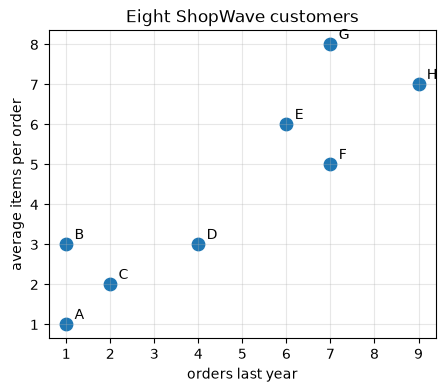

In [3]:
plt.figure(figsize=(5, 4))
plt.scatter(points[:, 0], points[:, 1], s=80)
for n, (x, y) in zip(names, points):
    plt.annotate(n, (x, y), xytext=(6, 4), textcoords="offset points")
plt.xlabel("orders last year"); plt.ylabel("average items per order")
plt.title("Eight ShopWave customers"); plt.grid(alpha=.3); plt.show()

## 2. K-Means in ten lines

The function below *is* K-Means. It yields one snapshot per iteration so we can print the tables.

In [4]:
def kmeans_by_hand(points, centroids, max_iter=10):
    """Plain K-Means: assign to nearest centroid, move centroids to the mean, repeat."""
    labels = None
    for it in range(1, max_iter + 1):
        dist = np.sqrt(((points[:, None, :] - centroids[None, :, :]) ** 2).sum(axis=2))
        new_labels = dist.argmin(axis=1)                         # assignment step
        inertia = ((points - centroids[new_labels]) ** 2).sum()
        yield it, centroids.copy(), dist, new_labels, inertia
        if labels is not None and (new_labels == labels).all():
            return                                               # nothing changed: converged
        labels = new_labels
        centroids = np.array([points[labels == j].mean(axis=0)   # update step
                              for j in range(len(centroids))])

In [5]:
start = points[[0, 3]]                # centroids start on customers A and D
history = list(kmeans_by_hand(points, start))

for it, cents, dist, labels, inertia in history:
    print(f"Iteration {it}: centroids {cents.round(2).tolist()}")
    table = pd.DataFrame(dist.T.round(2), index=["to c1", "to c2"], columns=names)
    table.loc["cluster"] = labels + 1
    print(table.to_string(), "\n")
    print(f"inertia (each customer to its assigned centroid): {inertia:.2f}\n")

Iteration 1: centroids [[1.0, 1.0], [4.0, 3.0]]
            A    B     C     D     E     F     G     H
to c1    0.00  2.0  1.41  3.61  7.07  7.21  9.22  10.0
to c2    3.61  3.0  2.24  0.00  3.61  3.61  5.83   6.4
cluster  1.00  1.0  1.00  2.00  2.00  2.00  2.00   2.0 

inertia (each customer to its assigned centroid): 107.00

Iteration 2: centroids [[1.33, 2.0], [6.6, 5.8]]
            A     B     C     D     E     F     G     H
to c1    1.05  1.05  0.67  2.85  6.15  6.41  8.25  9.15
to c2    7.38  6.26  5.97  3.82  0.63  0.89  2.24  2.68
cluster  1.00  1.00  1.00  1.00  2.00  2.00  2.00  2.00 

inertia (each customer to its assigned centroid): 24.18

Iteration 3: centroids [[2.0, 2.25], [7.25, 6.5]]
            A     B     C     D     E     F     G     H
to c1    1.60  1.25  0.25  2.14  5.48  5.71  7.62  8.46
to c2    8.33  7.16  6.91  4.78  1.35  1.52  1.52  1.82
cluster  1.00  1.00  1.00  1.00  2.00  2.00  2.00  2.00 

inertia (each customer to its assigned centroid): 18.50



Compare with your paper: D sits in cluster 2 after iteration 1 and moves to cluster 1 in iteration 2. In iteration 3 nothing changes, so the loop stops. Inertia falls 107 → 24.18 → 18.5.

### Watching the centroids move

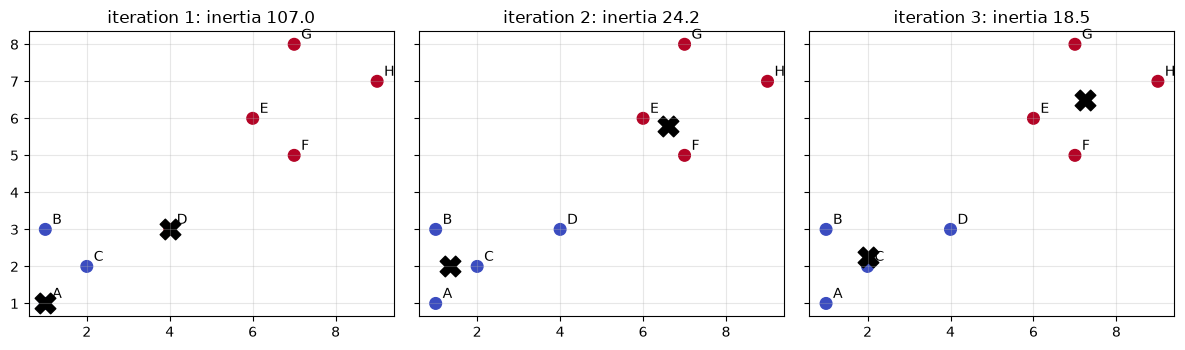

In [6]:
fig, axes = plt.subplots(1, len(history), figsize=(4 * len(history), 3.6), sharey=True)
for ax, (it, cents, dist, labels, inertia) in zip(axes, history):
    ax.scatter(points[:, 0], points[:, 1], c=labels, cmap="coolwarm", s=70)
    ax.scatter(cents[:, 0], cents[:, 1], marker="X", s=220, c="black")
    for n, (x, y) in zip(names, points):
        ax.annotate(n, (x, y), xytext=(5, 4), textcoords="offset points")
    ax.set_title(f"iteration {it}: inertia {inertia:.1f}"); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

### The final inertia, by hand

Squared distance from each customer to its own final centroid.

In [7]:
final_cents, final_labels = history[-1][1], history[-1][3]
sq = (points - final_cents[final_labels]) ** 2
inertia_table = pd.DataFrame({"(x-cx)²": sq[:, 0], "(y-cy)²": sq[:, 1], "sum": sq.sum(axis=1)}, index=names)
print(inertia_table.T.round(4).to_string())
print(f"\ncluster 1: {inertia_table['sum'][final_labels == 0].sum()},  "
      f"cluster 2: {inertia_table['sum'][final_labels == 1].sum()},  total: {inertia_table['sum'].sum()}")

              A       B       C       D       E       F       G       H
(x-cx)²  1.0000  1.0000  0.0000  4.0000  1.5625  0.0625  0.0625  3.0625
(y-cy)²  1.5625  0.5625  0.0625  0.5625  0.2500  2.2500  2.2500  0.2500
sum      2.5625  1.5625  0.0625  4.5625  1.8125  2.3125  2.3125  3.3125

cluster 1: 8.75,  cluster 2: 9.75,  total: 18.5


## 3. scikit-learn agrees

Give `KMeans` the same starting centroids and one run (`n_init=1`).

In [8]:
from sklearn.cluster import KMeans

km = KMeans(n_clusters=2, init=points[[0, 3]], n_init=1).fit(points)
print("centroids:", km.cluster_centers_.round(2).tolist())
print("inertia:  ", km.inertia_)
print("labels:   ", km.labels_)
print("iterations:", km.n_iter_)

centroids: [[2.0, 2.25], [7.25, 6.5]]
inertia:   18.5
labels:    [0 0 0 0 1 1 1 1]
iterations: 3


## 4. Bad starts and local minima

With $k = 3$, where the centroids start matters. Ten runs with purely random starts (`init="random", n_init=1`):

In [9]:
for seed in range(10):
    km = KMeans(n_clusters=3, init="random", n_init=1, random_state=seed).fit(points)
    groups = ["".join(n for n, l in zip(names, km.labels_) if l == j) for j in range(3)]
    print(f"seed {seed}: inertia {km.inertia_:6.2f}   groups {sorted(groups)}")

seed 0: inertia  15.25   groups ['ABCD', 'EG', 'FH']
seed 1: inertia  12.42   groups ['ABC', 'D', 'EFGH']
seed 2: inertia  12.42   groups ['ABC', 'D', 'EFGH']
seed 3: inertia  15.25   groups ['ABCD', 'EG', 'FH']
seed 4: inertia  12.25   groups ['ABCD', 'EF', 'GH']
seed 5: inertia  15.25   groups ['ABCD', 'EG', 'FH']
seed 6: inertia  15.25   groups ['ABCD', 'EG', 'FH']
seed 7: inertia  12.42   groups ['ABC', 'D', 'EFGH']
seed 8: inertia  15.25   groups ['ABCD', 'EG', 'FH']
seed 9: inertia  12.42   groups ['ABC', 'D', 'EFGH']


Three different final answers. K-Means stopped every time, but sometimes in a worse place (a **local minimum**): it splits the big buyers diagonally into {E, G} and {F, H} (inertia 15.25), or peels D off on its own (12.42). The best of the three, 12.25, keeps {A, B, C, D} together and splits the big buyers into {E, F} and {G, H}. From a bad start, K-Means cannot "see" that better answer: each step only improves on where it already is.

The fix is the default settings: **k-means++** chooses starting centroids that are spread out, and `n_init=10` runs ten starts and keeps the lowest inertia.

In [10]:
best = KMeans(n_clusters=3, n_init=10, random_state=42).fit(points)       # k-means++ is the default init
groups = ["".join(n for n, l in zip(names, best.labels_) if l == j) for j in range(3)]
print(f"k-means++, 10 starts: inertia {best.inertia_:.2f}   groups {sorted(groups)}")

k-means++, 10 starts: inertia 12.25   groups ['ABCD', 'EF', 'GH']


## 5. Scaling: the real customers

Now all 4,338 ShopWave customers, described by recency (days), frequency (orders) and monetary (£). First, without any transformation.

In [11]:
import sys
sys.path.insert(0, str(data_path("download.py").parent))
from download import load_retail

raw = load_retail("Year 2010-2011")
sales = raw[~raw["Invoice"].astype(str).str.startswith("C")]
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
sales = sales.assign(Revenue=sales["Quantity"] * sales["Price"])

snapshot = sales["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)    # 2011-12-10
rfm = sales.groupby("Customer ID").agg(
    recency=("InvoiceDate", lambda d: (snapshot - d.max()).days),
    frequency=("Invoice", "nunique"),
    monetary=("Revenue", "sum"))
print(f"{len(sales):,} rows, {len(rfm):,} customers, snapshot {snapshot.date()}")

392,693 rows, 4,338 customers, snapshot 2011-12-10


In [12]:
raw_labels = KMeans(n_clusters=4, n_init=10, random_state=42).fit_predict(rfm)
print("cluster sizes, raw numbers:", np.sort(np.bincount(raw_labels))[::-1])
rfm.assign(cluster=raw_labels).groupby("cluster").mean().round(0)

cluster sizes, raw numbers: [4300   31    5    2]


,recency,frequency,monetary
cluster,,,
0,93.0,4.0,1433.0
1,8.0,65.0,149740.0
2,30.0,43.0,46344.0
3,0.0,66.0,269932.0


One cluster holds almost everybody; the other three are spent on a few dozen giant spenders. Monetary is measured in hundreds or thousands of pounds, recency in tens of days, frequency in single orders: in raw distance, only money counts.

Now with a log transform (to tame the long tails) and standardisation (to put the three on the same footing):

In [13]:
from sklearn.preprocessing import StandardScaler

rfm_log = np.log1p(rfm)                         # tame the long right tails
X = StandardScaler().fit_transform(rfm_log)      # mean 0, std 1 per column
print("X shape:", X.shape)

X shape: (4338, 3)


In [14]:
scaled_labels = KMeans(n_clusters=4, n_init=10, random_state=42).fit_predict(X)
print("cluster sizes, log + scaled:", np.sort(np.bincount(scaled_labels))[::-1])
rfm.assign(cluster=scaled_labels).groupby("cluster").mean().round(1)

cluster sizes, log + scaled: [1635 1178  826  699]


,recency,frequency,monetary
cluster,,,
0,11.4,13.9,8194.3
1,180.3,1.3,344.2
2,17.3,2.2,555.8
3,70.0,4.1,1814.5


Four groups of usable size, each different on all three features. Lesson 06.3 decides whether four is the right number and gives them names.

### Why, in one calculation

In [15]:
P, Q, R = np.array([2, 500]), np.array([20, 520]), np.array([2, 900])     # (orders, spend £)
print(f"raw distance P-Q: {np.linalg.norm(P - Q):.1f}   P-R: {np.linalg.norm(P - R):.1f}")

raw distance P-Q: 26.9   P-R: 400.0


Raw distance says P and Q are near-twins, though Q orders ten times as often. Twenty pounds of spend counts the same as one order. Scaling fixes the units; logging stops a few huge values from stretching the scale for everyone else.

## Quiz answers

1. **Assign** each point to its nearest centroid; **update** each centroid to the mean of its points.
2. The mean position of the points in a cluster. It is usually **not** one of the customers.
3. Each step can only lower (or keep) the inertia, and there are only finitely many ways to assign points, so it must eventually stop changing.
4. Different **starting centroids** can lead to different local minima. Use **k-means++** initialisation and several starts (`n_init=10`), keeping the lowest inertia.
5. Monetary values are in the hundreds or thousands of pounds, so they dominate the distance; K-Means effectively clusters on money alone, and a few huge spenders take three of the four clusters.

**Next:** [06.3 How many clusters?](../03-choosing-k/)